# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Luarez, Karl Andrei 
- _Student No._: 2024-12430
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

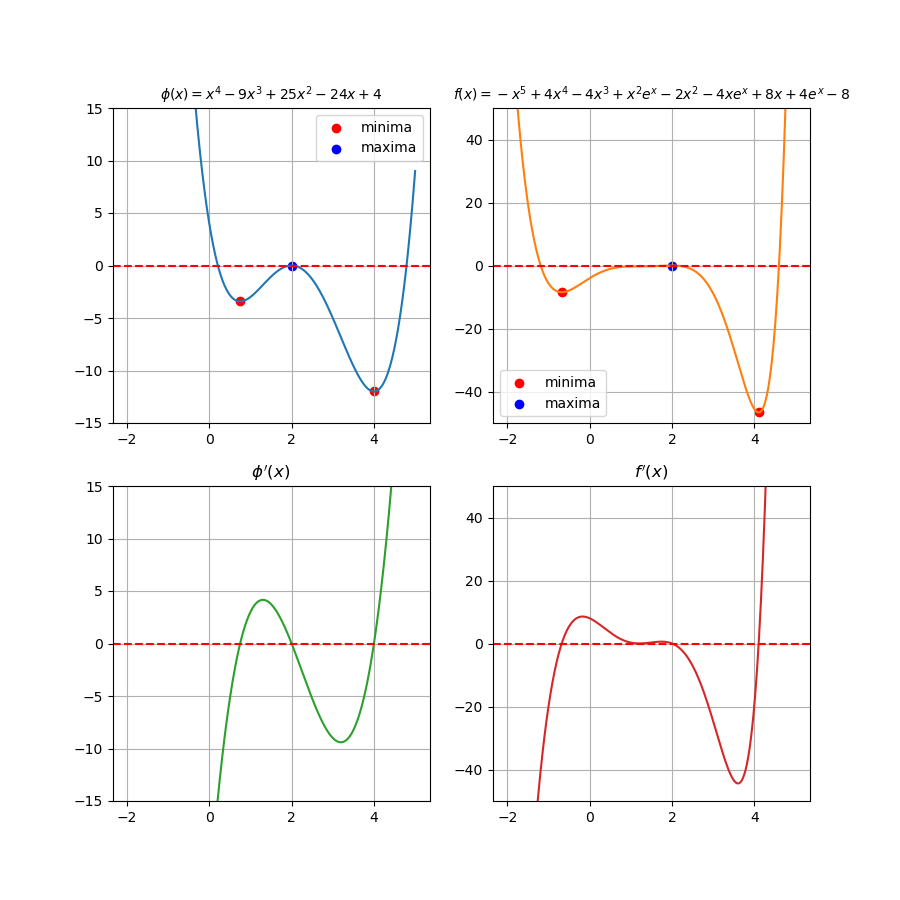
EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

We used the golden section search algorithm to find the local minimimum and maximum points in the figures shown above. If we consider the case that we use another number other than the golden ratio then the algorithm would fail because we choose our interval $(x_0,x_1)$ such that for an interior point $x_2$ splits the interval into a small and big subinterval $S$ and $B$, respectively, with another test point $x_3 \in B$. Then we compare the values $f(x_2)$ and $f(x_3)$ and introduce a new interval by removing one boundary depending on which is bigger or smaller. We strictly enforce that the new interval has the same width
$$
B = S + I
$$
and that the ratio must be invariant
$$
\frac{B}{S} = \frac{B-I}{I}.
$$
Combining the two solutions yields only one solution which is the golden ratio $\varphi \approx 1.618$, making it the only number that makes our algorithm work.
### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$
$$
\phi'(x) = 4x^3 - 27x^2 + 50x - 24
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$
$$
f'(x) = -5x^4 + 16x^3 + x^2e^x - 2xe^x - 4x + 8 
$$.

1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [142]:
# Define functions and their analytic derivatives
def phi(x):
    return x**4 -9*x**3 +25*x**2 - 24*x + 4
def dphi(x):
    return 4*x**3 -27*x**2 + 50*x - 24
def f(x):
  return -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 -4*x*np.exp(x) + 8*x + 4*np.exp(x) -8
def df(x):
  return (-5*x**4) + (16*x**3) - (12*x**2) + (x**2 * np.exp(x)) - (2*x*np.exp(x)) - (4*x) + 8


def minimum(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + np.sqrt(5))
    for k in range(1, kmax+1):
        x2 = x0 + (x1-x0)/(varphi+1) # From eq 5.97 in Gezerlis
        x3 = x0 + (x1-x0)*varphi/(varphi+1)

        if phi(x3) < phi(x2):
            x0 = x2 # Min at(x2,x1)

        else:
            x1 = x3

        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
        # print("{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}".format(k, xnew, xdiff, phi(xnew)))

        if abs(xdiff) < tol:
            break

        else:
            xnew = None
        
    return xnew, phi(xnew)

def maximum(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1+np.sqrt(5))
    for k in range(1,kmax+1):
        x2 = x0 + (x1-x0) / (varphi+1)
        x3 = x0 + (x1-x0) *varphi/(varphi+1)

        if phi(x3) < phi(x2):
            x1 = x3

        else:
            x0 = x2
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
        # print("{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}".format(k, xnew, xdiff, phi(xnew)))

        if abs(xdiff) < tol:
            break

        else:
            xnew = None
        
    return xnew, phi(xnew)  

phi_min = [minimum(phi,0,2), minimum(phi,2,5)]
phi_max = max(phi,0,3)
f_min = [minimum(f,-2,0), minimum(f,2,5)]
f_max = max(f,0,3)

print(f"local phi_min (x,y)= {phi_min}")
print(f"local phi_max (x,y)= {phi_max}")
print(f"local f_min (x,y)= {f_min}")
print(f"local f_max (x,y)= {f_max}")

local phi_min (x,y)= [(0.74999999604718, -3.4179687499999982), (3.9999999135537827, -11.999999999999972)]
local phi_max (x,y)= (2.0000000377371903, 0.0)
local f_min (x,y)= [(-0.6798620124829506, -8.467698098203567), (4.1033248426850415, -46.66216526150396)]
local f_max (x,y)= (2.0000000034137413, 0.0)


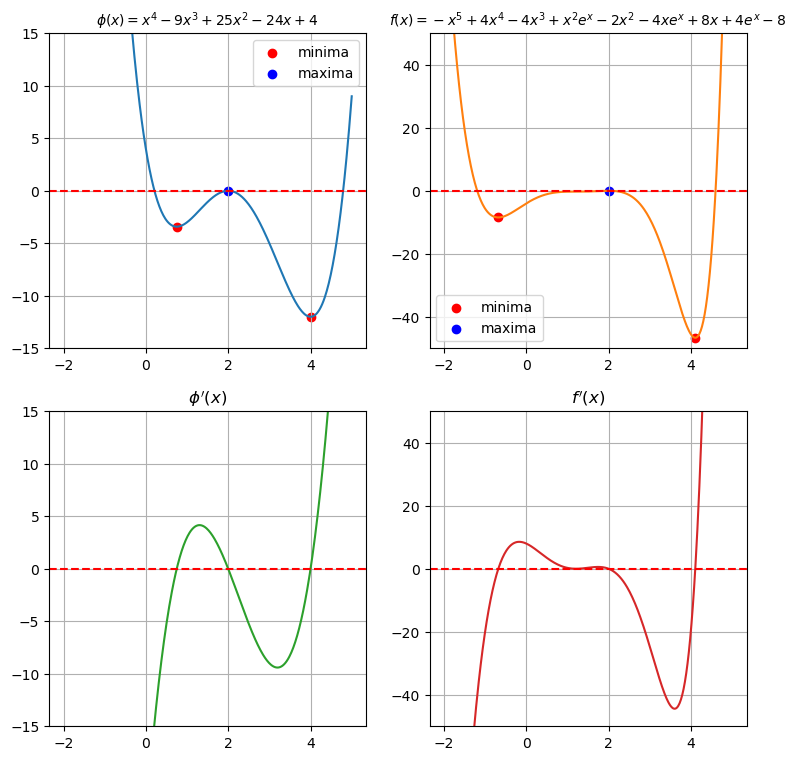

In [147]:
x = np.linspace(-2, 5,440)
y = np.sin(x ** 2)            

# Plotting
fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, phi(x))
axs[0, 0].scatter(phi_min[0][0], phi_min[0][1], label = 'minima', color = 'red')
axs[0, 0].scatter(phi_min[1][0], phi_min[1][1], color = 'red')
axs[0, 0].scatter(phi_max[0], phi_max[1], label = 'maxima', color = 'b')
axs[0, 0].set_title(r'$\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$', fontsize='10')
axs[0, 0].set_ylim(-15,15)
axs[0, 0].axhline(y=0, color='r', linestyle='--')
axs[0, 0].grid()
axs[0, 0].legend()

axs[0, 1].plot(x, f(x), 'tab:orange')
axs[0, 1].scatter(f_min[0][0], f_min[0][1], label = 'minima', color = 'red')
axs[0, 1].scatter(f_min[1][0], f_min[1][1], color = 'red')
axs[0, 1].scatter(f_max[0], f_max[1], label = 'maxima',color = 'blue')
axs[0, 1].set_title(r'$f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$',fontsize='10')
axs[0, 1].set_ylim(-50,50)
axs[0, 1].grid()
axs[0, 1].axhline(y=0, color='r', linestyle='--')
axs[0, 1].legend()

axs[1, 0].plot(x, dphi(x), 'tab:green')
axs[1, 0].set_title(r"$\phi'(x)$")
axs[1, 0].set_ylim(-15,15)
axs[1, 0].grid()
axs[1, 0].axhline(y=0, color='r', linestyle='--')

axs[1, 1].plot(x, df(x), 'tab:red')
axs[1, 1].set_title(r"$f'(x)$")
axs[1, 1].set_ylim(-50,50)
axs[1, 1].grid()
axs[1, 1].axhline(y=0, color='r', linestyle='--')
fig.show()
plt.savefig("Figures/Exercise 8 Figure.png")


#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

The algorithm in this function is quite similar to the one I considered an interval $(x_0,x_1)$ and two points in that interval $x_2$ and $x_3$ with formulas in terms of $x_0$ and $x_1$ taken from Eq. (5.97) in Gezerlis. Then I computed the value of the function $\phi(x)$ at $x_2$ and $x_3$ such that if a new smaller interval is the one containing the greater or lesser function (depending if the algorithm is looking for a local maximum or minimum). Then I repeated this process until $|x_0-x_1|$ is less than the tolerance or until we hit the max number of iterations.